# Group E+F Multiple Regression

In [1]:
import pandas as pd
import numpy as np
import os
import statsmodels.api as sm
import matplotlib.pyplot as plt

# --- Paths ---
elpac_clean_dir = "../1095 Data/ELPAC/Cleaned"
enrollment_dir  = "../1095 Data/Enrollment"

os.makedirs("plots", exist_ok=True)

# --- Load Group E and F SSIDs ---
group_e = pd.read_csv("group_e_ssids.csv")
group_f = pd.read_csv("group_f_ssids.csv")
group_e["Group"] = "E"
group_f["Group"] = "F"
group_ef = pd.concat([group_e, group_f], ignore_index=True)
group_ef_ssids = set(group_ef["SSID"])
print(f"Group E: {len(group_e):,} students")
print(f"Group F: {len(group_f):,} students")
print(f"Group E+F: {len(group_ef_ssids):,} students")

# --- Load Cleaned ELPAC files ---
initial_22 = pd.read_csv(os.path.join(elpac_clean_dir, "InitialElpac_22_clean.csv"), low_memory=False)
initial_22 = initial_22.apply(lambda col: col.str.strip() if col.dtype == "object" else col)
initial_22["OverallPL"]         = initial_22["OverallPL"].astype(str).str.strip()
initial_22["TestStartDate"]     = pd.to_datetime(initial_22["TestStartDate"], errors="coerce")
initial_22["OverallScaleScore"] = pd.to_numeric(initial_22["OverallScaleScore"], errors="coerce")

summative_files = {
    1: "SummativeElpac_22_clean.csv",
    2: "SummativeElpac_23_clean.csv",
    3: "SummativeElpac_24_clean.csv",
}

summative_dfs = {}
for year_num, filename in summative_files.items():
    df = pd.read_csv(os.path.join(elpac_clean_dir, filename), low_memory=False)
    df = df.apply(lambda col: col.str.strip() if col.dtype == "object" else col)
    df["OverallScaleScore"] = pd.to_numeric(df["OverallScaleScore"], errors="coerce")
    df["TestStartDate"]     = pd.to_datetime(df["TestStartDate"], errors="coerce")
    summative_dfs[year_num] = df
    print(f"Summative {year_num}: {len(df):,} rows")

# --- Load Enrollment files ---
enrollment_files = {
    "2021-22": "CEnrollment_21-22.csv",
    "2022-23": "CEnrollment_22-23.csv",
    "2023-24": "CEnrollment_23-24.csv",
}

enrollment_dfs = {}
for label, filename in enrollment_files.items():
    enrollment_dfs[label] = pd.read_csv(os.path.join(enrollment_dir, filename), low_memory=False)
    print(f"Enrollment {label}: {len(enrollment_dfs[label]):,} rows")

enrollment_all   = pd.concat(enrollment_dfs.values(), ignore_index=True)
enrollment_group = (
    enrollment_all[enrollment_all["SSID"].isin(group_ef_ssids)]
    .drop_duplicates(subset="SSID", keep="first")
)
print(f"\nE+F enrollment records: {len(enrollment_group):,}")

Group E: 28,707 students
Group F: 4,196 students
Group E+F: 32,903 students
Summative 1: 302,476 rows
Summative 2: 296,681 rows
Summative 3: 291,920 rows
Enrollment 2021-22: 1,519,618 rows
Enrollment 2022-23: 1,467,738 rows
Enrollment 2023-24: 1,471,765 rows

E+F enrollment records: 32,903


In [2]:
# --- Build per-student initial score and summative 3 score ---
initial_scores = (
    initial_22[initial_22["SSID"].isin(group_ef_ssids)]
    [["SSID", "OverallScaleScore", "TestStartDate"]]
    .dropna()
    .rename(columns={"OverallScaleScore": "InitialScore", "TestStartDate": "InitialDate"})
)

summ3_scores = (
    summative_dfs[3][summative_dfs[3]["SSID"].isin(group_ef_ssids)]
    [["SSID", "OverallScaleScore"]]
    .dropna()
    .rename(columns={"OverallScaleScore": "Summative3Score"})
)

# --- Build regression dataframe ---
reg_df = group_ef.merge(initial_scores, on="SSID", how="inner")
reg_df = reg_df.merge(summ3_scores,    on="SSID", how="inner")

# --- Compute score gain ---
reg_df["ScoreGain"] = reg_df["Summative3Score"] - reg_df["InitialScore"]

# --- Merge demographic variables from 2021-22 enrollment ---
demo_cols = [
    "SSID",
    "GradeLevelCode",
    "SocioeconomicallyDisadvantaged",
    "TitleIPartCMigrant",
    "HomelessProgram",
    "Foster",
    "UnaccompaniedYouthIndicator",
    "PrimaryLanguageCode",
    "StudentGenderCode",
    "ParentGuardianHighestEducationLevelCode",
    "StudentBirthCountryCode",
    "RaceEthnicity",
]

demo_2022 = (
    enrollment_dfs["2021-22"][demo_cols]
    .dropna(subset=["SSID"])
    .drop_duplicates(subset="SSID", keep="first")
)

reg_df = reg_df.merge(demo_2022, on="SSID", how="left")

# --- Simplify PrimaryLanguageCode to Spanish / Non-Spanish ---
reg_df["SpanishSpeaker"] = (reg_df["PrimaryLanguageCode"].astype(str).str.strip() == "01").astype(int)

# --- Simplify Birth Country to US-born / Foreign-born ---
reg_df["USBorn"] = (reg_df["StudentBirthCountryCode"].astype(str).str.strip() == "US").astype(int)

print(f"Regression dataset: {len(reg_df):,} students")
print(f"\nScore Gain summary:")
print(reg_df["ScoreGain"].describe())
print(f"\nMissing values per column:")
print(reg_df.isnull().sum()[reg_df.isnull().sum() > 0])

Regression dataset: 32,903 students

Score Gain summary:
count    32903.000000
mean      1230.952345
std         90.939150
min        874.000000
25%       1164.000000
50%       1239.000000
75%       1295.000000
max       1657.000000
Name: ScoreGain, dtype: float64

Missing values per column:
UnaccompaniedYouthIndicator                30799
PrimaryLanguageCode                          489
ParentGuardianHighestEducationLevelCode       68
dtype: int64


In [6]:
# --- Deep diagnostic ---
print("=== X_const dtypes that are object ===")
obj_cols = X_const.columns[X_const.dtypes == object].tolist()
print(f"Object columns: {obj_cols}")

print("\n=== Sample values from object columns ===")
for col in obj_cols[:5]:
    print(f"  {col}: {X_const[col].unique()[:10]}")

print("\n=== Check numpy conversion ===")
try:
    arr = np.asarray(X_const)
    print(f"Array dtype: {arr.dtype}")
    print(f"Array shape: {arr.shape}")
except Exception as e:
    print(f"Error: {e}")

print("\n=== y dtype ===")
print(f"y dtype: {y.dtype}")
print(f"y sample: {y.head()}")

# --- Nuclear fix: convert everything to float64 via numpy ---
X_np = np.asarray(X_const.values, dtype=np.float64)
y_np = np.asarray(y.values,       dtype=np.float64)

print(f"\nAfter numpy conversion:")
print(f"X dtype: {X_np.dtype}, shape: {X_np.shape}")
print(f"y dtype: {y_np.dtype}, shape: {y_np.shape}")

# --- Run OLS with numpy arrays instead of dataframes ---
model = sm.OLS(y_np, X_np).fit()
print(model.summary())

=== X_const dtypes that are object ===
Object columns: []

=== Sample values from object columns ===

=== Check numpy conversion ===
Array dtype: object
Array shape: (32903, 38)

=== y dtype ===
y dtype: float64
y sample: 0    1209.0
1    1306.0
2    1347.0
3    1084.0
4    1239.0
Name: ScoreGain, dtype: float64

After numpy conversion:
X dtype: float64, shape: (32903, 38)
y dtype: float64, shape: (32903,)
                            OLS Regression Results                            
Dep. Variable:                      y   R-squared:                       0.626
Model:                            OLS   Adj. R-squared:                  0.626
Method:                 Least Squares   F-statistic:                     1488.
Date:                Mon, 29 Jun 2026   Prob (F-statistic):               0.00
Time:                        18:27:05   Log-Likelihood:            -1.7890e+05
No. Observations:               32903   AIC:                         3.579e+05
Df Residuals:                   32865

In [7]:
# --- Rebuild with proper variable names ---
feature_names = X_const.columns.tolist()

model = sm.OLS(y_np, X_np).fit()

# --- Build clean results table ---
results = pd.DataFrame({
    "Variable":    feature_names,
    "Coefficient": model.params,
    "StdErr":      model.bse,
    "T-Stat":      model.tvalues,
    "P-Value":     model.pvalues,
    "Significant": model.pvalues < 0.05
})

results = results.sort_values("P-Value")

print(f"Model R²:            {model.rsquared:.4f}")
print(f"Adjusted R²:         {model.rsquared_adj:.4f}")
print(f"F-statistic:         {model.fvalue:.2f}")
print(f"F-statistic p-value: {model.f_pvalue:.4e}")
print(f"\nTotal predictors:    {len(results)}")
print(f"Significant (p<0.05): {results['Significant'].sum()}")

print("\n=== All Results ===")
pd.set_option("display.max_rows", None)
pd.set_option("display.float_format", "{:.4f}".format)
print(results.to_string(index=False))

# --- Export full results to CSV ---
results.to_csv("regression_results_group_ef.csv", index=False)
print("\nSaved: regression_results_group_ef.csv")

Model R²:            0.6262
Adjusted R²:         0.6258
F-statistic:         1488.21
F-statistic p-value: 0.0000e+00

Total predictors:    38
Significant (p<0.05): 26

=== All Results ===
                                    Variable  Coefficient  StdErr    T-Stat  P-Value  Significant
                                       const    1428.6859  2.3553  606.5776   0.0000         True
                                InitialScore      -0.7296  0.0050 -146.9301   0.0000         True
                           GradeLevelCode_09      30.8564  1.7137   18.0054   0.0000         True
                           GradeLevelCode_04      33.8767  2.2059   15.3576   0.0000         True
                           GradeLevelCode_05      35.8016  2.3465   15.2574   0.0000         True
                           GradeLevelCode_03      32.7863  2.1523   15.2332   0.0000         True
                           GradeLevelCode_06      31.9674  2.3212   13.7721   0.0000         True
                           G

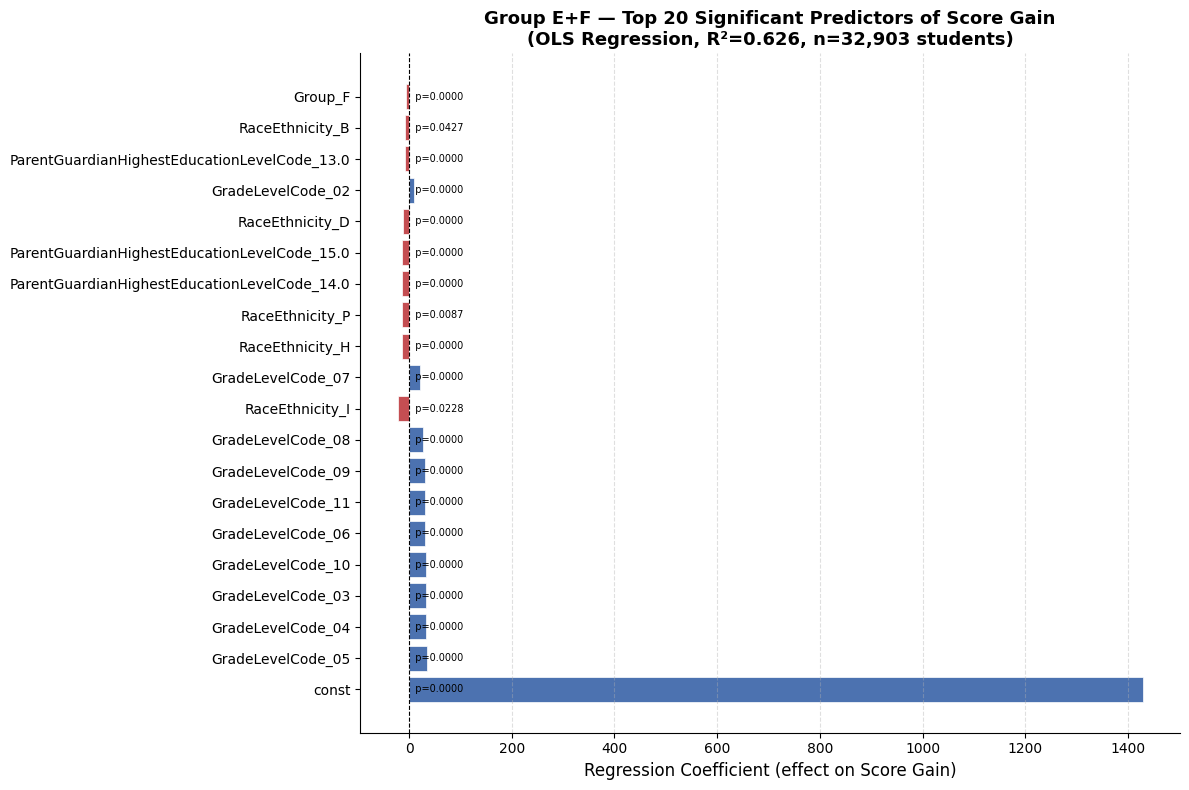

Saved: plots/group_ef_regression_top20.png


In [8]:
# --- Plot top 20 significant predictors by coefficient magnitude ---
significant = results[results["Significant"]].copy()
significant = significant.reindex(
    significant["Coefficient"].abs().sort_values(ascending=False).index
)
top20 = significant.head(20)

fig, ax = plt.subplots(figsize=(12, 8))
colors = ["#4C72B0" if c >= 0 else "#C44E52" for c in top20["Coefficient"]]
ax.barh(top20["Variable"], top20["Coefficient"],
        color=colors, edgecolor="white", linewidth=0.5)

# Add p-value labels
for i, (_, row) in enumerate(top20.iterrows()):
    ax.text(0, i, f"  p={row['P-Value']:.4f}",
            va="center", fontsize=7, color="black")

ax.axvline(0, color="black", linewidth=0.8, linestyle="--")
ax.set_xlabel("Regression Coefficient (effect on Score Gain)", fontsize=12)
ax.set_title("Group E+F — Top 20 Significant Predictors of Score Gain\n"
             f"(OLS Regression, R²={model.rsquared:.3f}, n={len(y_np):,} students)",
             fontsize=13, fontweight="bold")
ax.grid(axis="x", linestyle="--", alpha=0.4)
ax.spines[["top", "right"]].set_visible(False)

plt.tight_layout()
plt.savefig("plots/group_ef_regression_top20.png", dpi=150, bbox_inches="tight")
plt.show()
print("Saved: plots/group_ef_regression_top20.png")

# Group E+F Regression Analysis: Key Findings

## Overall Model Strength

The model explains about 63% of the variation in score gains across students (R² = 0.626), which is quite strong for education data. This means the demographic variables included are genuinely predictive of how much a student improves over the three-year period.

---

## Key Findings by Variable

### Starting Score (InitialScore, coefficient = -0.73)

The single strongest predictor. Students who start with a lower initial score gain more points over the three years. This is expected — students who start very low have more room to grow. For every 10 points higher a student starts, they gain about 7 fewer points over the three years.

### Grade Level

Almost all grade levels show significantly higher gains than the reference group (Grade 1). The strongest gains are seen in Grades 3–6 and Grades 9–10 (around 30–36 extra points). Grade 2 shows a much smaller advantage (+8.7 points). This suggests the program is most effective for elementary and high school students above first grade.

| Grade | Coefficient | Significant |
|-------|-------------|-------------|
| Grade 2 | +8.7 | Yes |
| Grade 3 | +32.8 | Yes |
| Grade 4 | +33.9 | Yes |
| Grade 5 | +35.8 | Yes |
| Grade 6 | +32.0 | Yes |
| Grade 7 | +21.5 | Yes |
| Grade 8 | +26.5 | Yes |
| Grade 9 | +30.9 | Yes |
| Grade 10 | +32.1 | Yes |
| Grade 11 | +31.4 | Yes |

### Parent Education Level

Counterintuitively, students whose parents have higher education levels (college graduate, graduate school, or declined to state) show *lower* gains than students whose parents did not graduate high school (the reference group). After controlling for starting score, this may reflect that students from less-educated families are benefiting more from the program's structured support.

| Parent Education Level | Coefficient | Significant |
|------------------------|-------------|-------------|
| High School Graduate | +3.4 | No |
| Some College | -5.6 | Yes |
| College Graduate | -8.0 | Yes |
| Graduate School | -14.0 | Yes |
| Declined to State | -13.8 | Yes |

### Race / Ethnicity

Several race/ethnicity groups show lower gains than the reference group. White and Filipino students showed no statistically significant difference from the reference group.

| Race / Ethnicity | Coefficient | Significant |
|------------------|-------------|-------------|
| Hispanic/Latino | -14.7 | Yes |
| Pacific Islander | -14.6 | Yes |
| American Indian/Alaska Native | -22.3 | Yes |
| Asian | -11.2 | Yes |
| Black/African American | -6.9 | Yes |
| White | +1.8 | No |
| Filipino | +0.3 | No |

### Gender

Male students gain about 3.7 fewer points than female students — a small but statistically significant difference.

### Group E vs. Group F (coefficient = -5.87)

Students who started as Intermediate English Learners (Group F) gain about 5.9 fewer points than students who started as Novice English Learners (Group E), even after controlling for their initial score. This suggests Novice learners benefit slightly more from the program in terms of raw score gain.

### Homeless Students (coefficient = -5.3)

Homeless students gain about 5.3 fewer points than non-homeless students — a meaningful and significant gap that suggests housing instability is a barrier to language learning progress.

### Socioeconomically Disadvantaged (coefficient = -1.77)

A small but statistically significant negative effect — socioeconomically disadvantaged students gain about 1.8 fewer points. The effect is smaller than might be expected, possibly because many students in this group are already captured by other variables like parent education.

### US-Born Students (coefficient = -2.5)

Students born in the US gain about 2.5 fewer points than foreign-born students. This may reflect that foreign-born students are newer to English instruction and therefore benefit more from the program.

---

## Variables with No Significant Effect

The following variables showed no meaningful effect on score gain after controlling for everything else:

- Spanish speaker (Primary Language)
- Migrant status
- Unaccompanied Youth
- Foster care
- White race/ethnicity
- Filipino race/ethnicity
- Grade 12

---

## Bottom Line

The most important factors driving score gain are:

1. **Starting score** — lower starters gain more
2. **Grade level** — middle and upper elementary and high school students perform best
3. **Race/ethnicity** — meaningful gaps exist across racial and ethnic groups
4. **Parent education level** — counterintuitively, higher parent education is associated with lower gains

The program appears to be working across all groups, but there are meaningful gaps in outcomes by race and socioeconomic circumstances that warrant further attention.